### BALL DETECTION

In [1]:
# read image from a file
# and display it using OpenCV
import cv2
import sys
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.backends.backend_tkagg as tkagg


In [2]:
def show_image(image, title="Image"):
    """Display an image using OpenCV."""
    # plot the image
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')  # Hide the axes
    plt.show()

In [3]:
def read_image(file_path):
    """Read an image from a file."""
    # Read the image
    image = cv2.imread(file_path, cv2.IMREAD_COLOR)
    if image is None:
        print(f"Error: Unable to read image from {file_path}")
        sys.exit(1)
    return image

Image shape: (1600, 2560, 3)


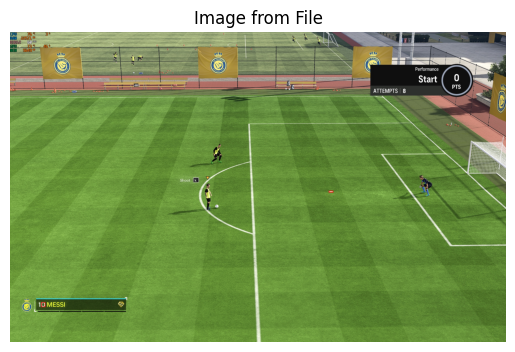

In [6]:
read_image_path = "./output_videos/ML_org_0.jpg"  # Replace with your image path
img = read_image(read_image_path)
# Convert BGR to RGB
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("Image shape:", img.shape)
# Display the image
show_image(img_rgb, title="Image from File")

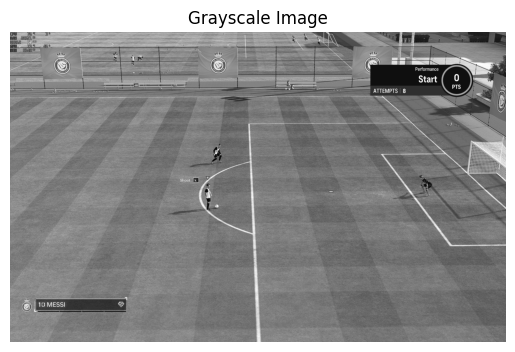

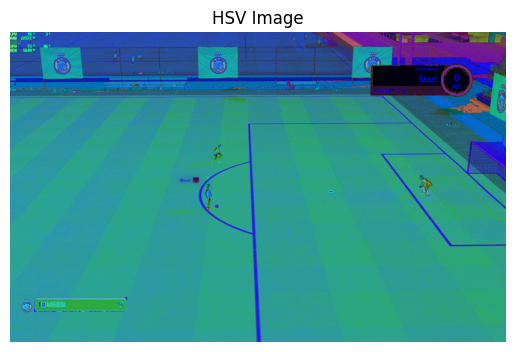

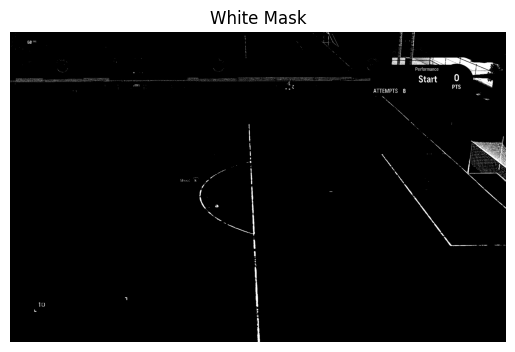

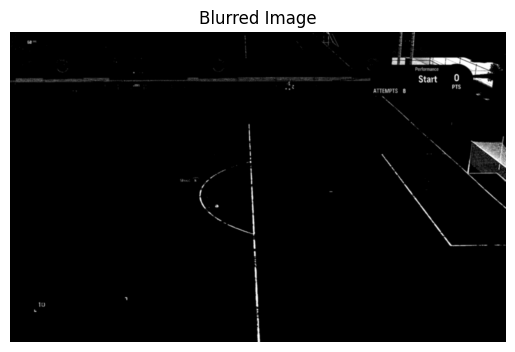

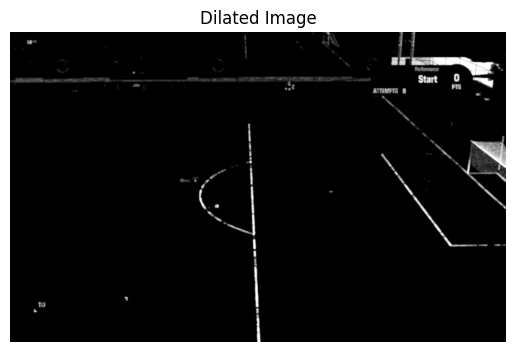

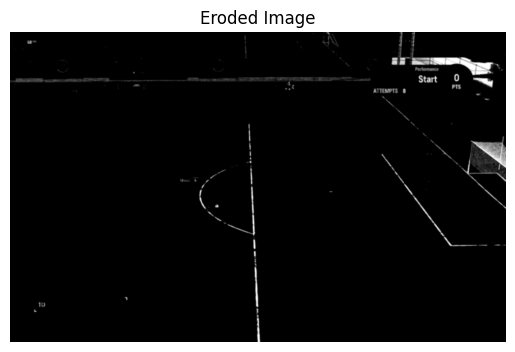

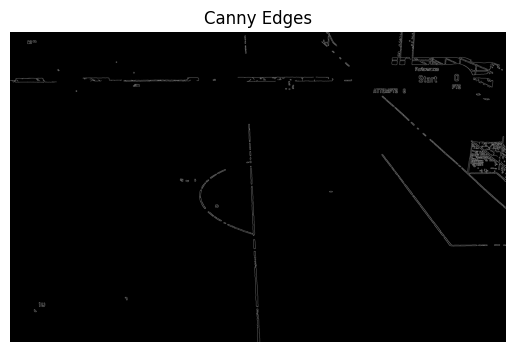

Found 166 potential ball(s)
Ball 1: Center at (2206, 190), Radius = 4
Ball 2: Center at (106, 56), Radius = 4
Ball 3: Center at (2414, 668), Radius = 4
Ball 4: Center at (2120, 250), Radius = 4
Ball 5: Center at (2318, 278), Radius = 4
Ball 6: Center at (2488, 254), Radius = 4
Ball 7: Center at (60, 254), Radius = 4
Ball 8: Center at (328, 250), Radius = 4
Ball 9: Center at (2406, 170), Radius = 4
Ball 10: Center at (2456, 610), Radius = 4
Ball 11: Center at (2484, 684), Radius = 4
Ball 12: Center at (1242, 670), Radius = 4
Ball 13: Center at (1854, 242), Radius = 4
Ball 14: Center at (1992, 310), Radius = 4
Ball 15: Center at (2176, 136), Radius = 4
Ball 16: Center at (2388, 586), Radius = 4
Ball 17: Center at (2508, 618), Radius = 4
Ball 18: Center at (2218, 1026), Radius = 4
Ball 19: Center at (2262, 1084), Radius = 4
Ball 20: Center at (440, 248), Radius = 4
Ball 21: Center at (664, 274), Radius = 4
Ball 22: Center at (1612, 48), Radius = 4
Ball 23: Center at (1718, 240), Radius = 

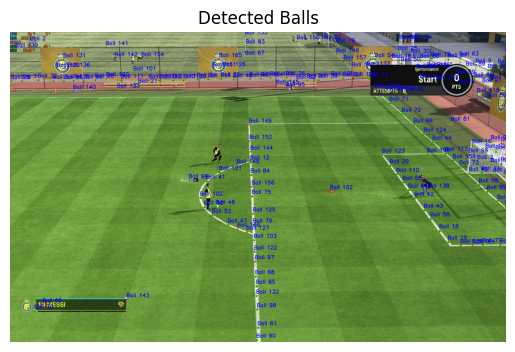

In [16]:
import cv2
import numpy as np
import argparse

def detect_white_ball(image_path):
    # Read the image
    image = cv2.imread(image_path)
    if image is None:
        print(f"Error: Could not read image at {image_path}")
        return None
    
    # Create a copy for drawing results
    output = image.copy()
    
    # Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    plt.imshow(gray, cmap='gray')
    plt.title("Grayscale Image")
    plt.axis('off')
    plt.show()
    
    
    # Convert to HSV color space
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    plt.imshow(hsv)
    plt.title("HSV Image")
    plt.axis('off')
    plt.show()
    
    
    # Define range for white color in HSV
    # White is tricky in HSV - we'll use high Value and low Saturation
    lower_white = np.array([0, 0, 200])
    upper_white = np.array([180, 30, 255])
    
    # Create mask for white color
    white_mask = cv2.inRange(hsv, lower_white, upper_white)
    plt.imshow(white_mask, cmap='gray')
    plt.title("White Mask")
    plt.axis('off')
    plt.show()
    
    
    # Apply Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(white_mask, (9, 9), 2)
    
    plt.imshow(blurred, cmap='gray')
    plt.title("Blurred Image")
    plt.axis('off')
    plt.show()
    
    # apply circular dilation
    kernel = np.ones((5, 5), np.uint8)
    dilated = cv2.dilate(blurred, kernel, iterations=1)
    plt.imshow(dilated, cmap='gray')
    plt.title("Dilated Image")
    plt.axis('off')
    plt.show()
    
    # Erode the image to remove small noise
    eroded = cv2.erode(dilated, kernel, iterations=1)
    plt.imshow(eroded, cmap='gray')
    plt.title("Eroded Image")
    plt.axis('off')
    plt.show()
    # Apply Canny edge detection
    edges = cv2.Canny(blurred, 50, 150)
    plt.imshow(edges, cmap='gray')
    plt.title("Canny Edges")
    plt.axis('off')
    plt.show()
    
    # Use Hough Circle Transform to detect circles
    circles = cv2.HoughCircles(
        eroded,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=50,
        param1=50,
        param2=1,
        minRadius=1,
        maxRadius=5
    )
    
    # If circles are found
    if circles is not None:
        # Convert circles to integers
        circles = np.uint16(np.around(circles))
        
        # Sort circles by confidence (third parameter in Hough output)
        # and take the most confident ones
        best_circles = sorted(circles[0], key=lambda x: x[2], reverse=True)
        
        print(f"Found {len(best_circles)} potential ball(s)")
        
        # Draw detected circles
        for i, (x, y, r) in enumerate(best_circles):
            # Draw the outer circle
            cv2.circle(output, (x, y), r, (0, 255, 0), 4)
            # Draw the center
            cv2.circle(output, (x, y), 2, (0, 0, 255), 3)
            # Label with confidence value
            cv2.putText(output, f"Ball {i+1}", (x-r, y-r-10), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)
            print(f"Ball {i+1}: Center at ({x}, {y}), Radius = {r}")
        
        # Save the result
        result_path = "detected_ball.jpg"
        cv2.imwrite(result_path, output)
        print(f"Result saved as {result_path}")
        
        return output, best_circles
    else:
        print("No circles found")
        return output, None

if __name__ == "__main__":

    
    # Detect balls
    result_img, circles = detect_white_ball("./output_videos/ML_org_0.jpg")
    
    # Show results
    if result_img is not None:
        #plot the image with detected circles
        plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
        plt.title("Detected Balls")
        plt.axis('off')
        plt.show()
